In [1]:
# Customer Sales Analysis - Step 1: Load and explore the data

import pandas as pd
from google.colab import files

# Upload BOTH files at the same time
uploaded = files.upload()

customers = None
sales = None
for name in uploaded:
    if 'sales' in name.lower():
        sales = pd.read_csv(name)
    elif 'churn' in name.lower() or 'customer' in name.lower():
        customers = pd.read_csv(name)

if customers is None or sales is None:
    print("Error: please upload BOTH files (the customer file and the sales file).")
else:
    for title, df in [("CUSTOMER DATA", customers), ("SALES DATA", sales)]:
        print("=" * 50)
        print(title)
        print("=" * 50)
        print("Rows and columns:", df.shape)
        print()
        print(df.head())
        print()
        print("Data types:")
        print(df.dtypes)
        print()
        print("Missing values:")
        print(df.isnull().sum())
        print("Duplicate rows:", df.duplicated().sum())
        print()

    print("=" * 50)
    print("CAN WE JOIN THE TWO FILES?")
    print("=" * 50)
    print("Customer ID examples in customer file:", customers['CustomerID'].head(3).tolist())
    print("Customer ID examples in sales file:   ", sales['Customer_ID'].head(3).tolist())
    common = set(customers['CustomerID']) & set(sales['Customer_ID'])
    print("IDs that match exactly:", len(common))

Saving sales_data.csv to sales_data.csv
Saving customer_churn.csv to customer_churn.csv
CUSTOMER DATA
Rows and columns: (500, 9)

  CustomerID  Tenure  MonthlyCharges  TotalCharges        Contract  \
0     C00001       6              64          1540        One year   
1     C00002      21             113          1753  Month-to-month   
2     C00003      27              31          1455        Two year   
3     C00004      53              29          7150  Month-to-month   
4     C00005      16             185          1023        One year   

      PaymentMethod PaperlessBilling  SeniorCitizen  Churn  
0       Credit Card               No              1      0  
1  Electronic Check              Yes              1      0  
2       Credit Card               No              1      0  
3  Electronic Check               No              1      0  
4  Electronic Check               No              1      0  

Data types:
CustomerID          object
Tenure               int64
MonthlyCharges  

In [ ]:
# Step 2: Clean the data and join the two files

for col in ['Product', 'Region', 'Customer_ID']:
    sales[col] = sales[col].str.strip()
sales['Product'] = sales['Product'].str.title()
sales['Region'] = sales['Region'].str.title()
for col in ['CustomerID', 'Contract', 'PaymentMethod', 'PaperlessBilling']:
    customers[col] = customers[col].str.strip()

sales = sales.dropna().drop_duplicates()
customers = customers.dropna().drop_duplicates()

sales['Date'] = pd.to_datetime(sales['Date'])
sales['Year'] = sales['Date'].dt.year
sales['Month'] = sales['Date'].dt.month
sales['MonthName'] = sales['Date'].dt.strftime('%b')
sales['Quarter'] = 'Q' + sales['Date'].dt.quarter.astype(str)

sales['OrderSize'] = pd.cut(sales['Total_Sales'],
                            bins=[0, 100000, 200000, float('inf')],
                            labels=['Small', 'Medium', 'Large'])

customers['CustomerKey'] = customers['CustomerID'].str.extract(r'(\d+)')[0].astype(int)
sales['CustomerKey'] = sales['Customer_ID'].str.extract(r'(\d+)')[0].astype(int)

merged = sales.merge(customers, on='CustomerKey', how='left', validate='many_to_one')

print("Sales rows:", len(sales))
print("Customer rows:", len(customers))
print("Merged rows:", len(merged))
print("Sales rows with no customer match:", merged['CustomerID'].isnull().sum())
print()
print(merged[['Date', 'Product', 'Total_Sales', 'Customer_ID', 'CustomerID',
              'Contract', 'Tenure', 'Churn']].head())

Sales rows: 100
Customer rows: 500
Merged rows: 100
Sales rows with no customer match: 0

        Date     Product  Total_Sales Customer_ID CustomerID        Contract  \
0 2024-01-01       Phone       261100     CUST001     C00001        One year   
1 2024-01-02  Headphones        61624     CUST002     C00002  Month-to-month   
2 2024-01-03       Phone        43492     CUST003     C00003        Two year   
3 2024-01-04  Headphones        30895     CUST004     C00004  Month-to-month   
4 2024-01-05      Laptop       318680     CUST005     C00005        One year   

   Tenure  Churn  
0       6      0  
1      21      0  
2      27      0  
3      53      0  
4      16      0  


In [ ]:

# Step 3: Analysis - groupings (aggregations), top customers and pivot tables

# ---------- Aggregation 1: sales by product ----------
by_product = merged.groupby('Product').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Average_Order=('Total_Sales', 'mean'),
    Orders=('Total_Sales', 'count'),
    Units_Sold=('Quantity', 'sum')
).sort_values('Total_Sales', ascending=False).round(0)
print("1) SALES BY PRODUCT")
print(by_product)
print()

# ---------- Aggregation 2: sales by region ----------
by_region = merged.groupby('Region').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Average_Order=('Total_Sales', 'mean'),
    Orders=('Total_Sales', 'count')
).sort_values('Total_Sales', ascending=False).round(0)
print("2) SALES BY REGION")
print(by_region)
print()

# ---------- Aggregation 3: sales by month (in calendar order) ----------
by_month = merged.groupby(['Month', 'MonthName']).agg(
    Total_Sales=('Total_Sales', 'sum'),
    Orders=('Total_Sales', 'count')
).reset_index()
print("3) SALES BY MONTH")
print(by_month[['MonthName', 'Total_Sales', 'Orders']])
print()

# ---------- Aggregation 4: sales by contract type ----------
by_contract = merged.groupby('Contract').agg(
    Total_Sales=('Total_Sales', 'sum'),
    Average_Order=('Total_Sales', 'mean'),
    Orders=('Total_Sales', 'count')
).round(0)
print("4) SALES BY CONTRACT TYPE")
print(by_contract)
print()

# ---------- Top 5 customers ----------
top_customers = merged.nlargest(5, 'Total_Sales')[
    ['Customer_ID', 'Product', 'Region', 'Total_Sales', 'Contract', 'Tenure']]
top10_share = merged.nlargest(10, 'Total_Sales')['Total_Sales'].sum() / merged['Total_Sales'].sum() * 100
print("5) TOP 5 CUSTOMERS BY ORDER VALUE")
print(top_customers.to_string(index=False))
print(f"The top 10 orders make {top10_share:.1f}% of all sales.")
print()

# ---------- Pivot table 1: product x region ----------
pivot_product_region = pd.pivot_table(merged, values='Total_Sales',
                                      index='Product', columns='Region',
                                      aggfunc='sum', fill_value=0, margins=True)
print("PIVOT TABLE 1: SALES BY PRODUCT AND REGION")
print(pivot_product_region)
print()

# ---------- Pivot table 2: region x quarter ----------
pivot_region_quarter = pd.pivot_table(merged, values='Total_Sales',
                                      index='Region', columns='Quarter',
                                      aggfunc='sum', fill_value=0)
print("PIVOT TABLE 2: SALES BY REGION AND QUARTER")
print(pivot_region_quarter)
print()

# ---------- Customer retention (uses all 500 customers) ----------
customers['TenureGroup'] = pd.cut(customers['Tenure'], bins=[0, 12, 24, 48, 72],
                                  labels=['0-12 months', '13-24 months',
                                          '25-48 months', '49-72 months'])
churn_by_contract = (customers.groupby('Contract')['Churn'].agg(['mean', 'count']) * [100, 1]).round(1)
churn_by_contract.columns = ['Churn_Rate_%', 'Customers']
churn_by_tenure = (customers.groupby('TenureGroup', observed=True)['Churn'].agg(['mean', 'count']) * [100, 1]).round(1)
churn_by_tenure.columns = ['Churn_Rate_%', 'Customers']
print("CHURN RATE BY CONTRACT TYPE (all 500 customers)")
print(churn_by_contract)
print()
print("CHURN RATE BY HOW LONG THE CUSTOMER HAS STAYED")
print(churn_by_tenure)
print()
print(f"Overall churn rate: {customers['Churn'].mean() * 100:.1f}%")

# Average order value: customers who stayed (0) vs customers who left (1)
print()
print("AVERAGE ORDER VALUE: STAYED (0) vs LEFT (1)")
print(merged.groupby('Churn')['Total_Sales'].agg(['mean', 'count']).round(0))

1) SALES BY PRODUCT
            Total_Sales  Average_Order  Orders  Units_Sold
Product                                                   
Laptop          3889210       162050.0      24         136
Tablet          2884340       110936.0      26         127
Phone           2859394       142970.0      20         101
Headphones      1384033        92269.0      15          48
Monitor         1348071        89871.0      15          66

2) SALES BY REGION
        Total_Sales  Average_Order  Orders
Region                                    
North       3983635       142273.0      28
South       3737852       138439.0      27
East        2519639       132613.0      19
West        2123922        81689.0      26

3) SALES BY MONTH
  MonthName  Total_Sales  Orders
0       Jan      4120524      31
1       Feb      2656050      29
2       Mar      4485006      31
3       Apr      1103468       9

4) SALES BY CONTRACT TYPE
                Total_Sales  Average_Order  Orders
Contract                   

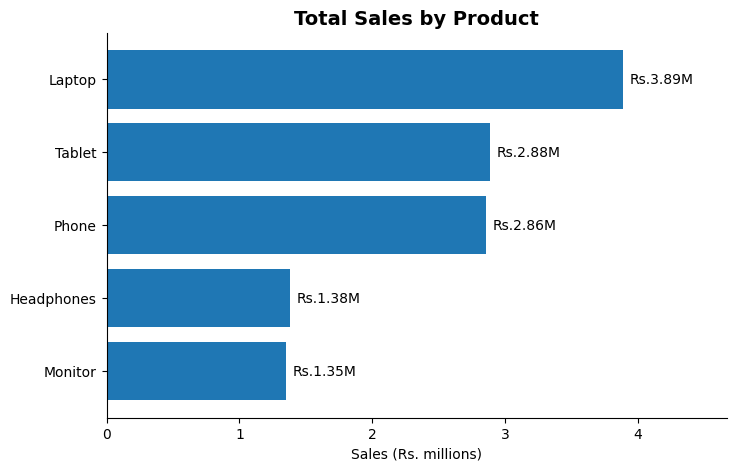

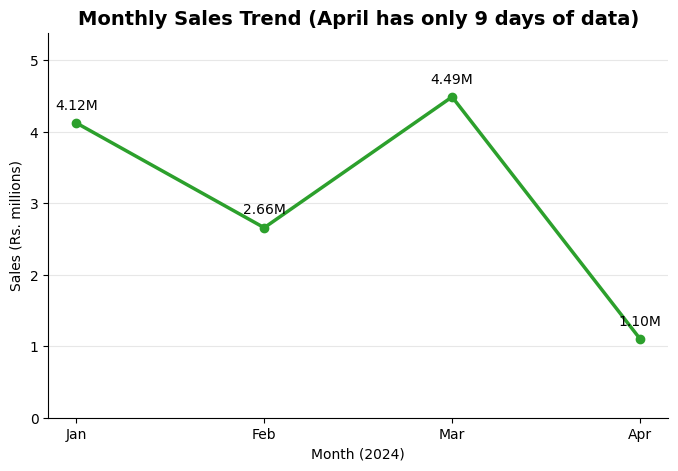

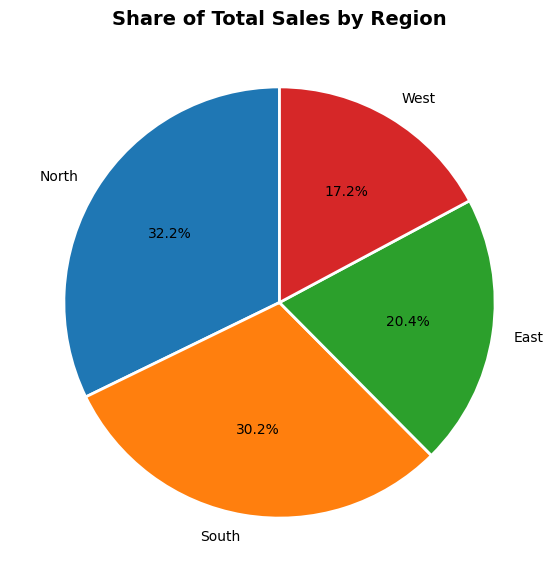

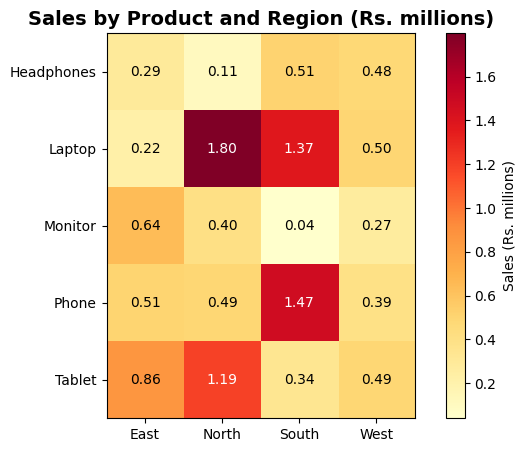

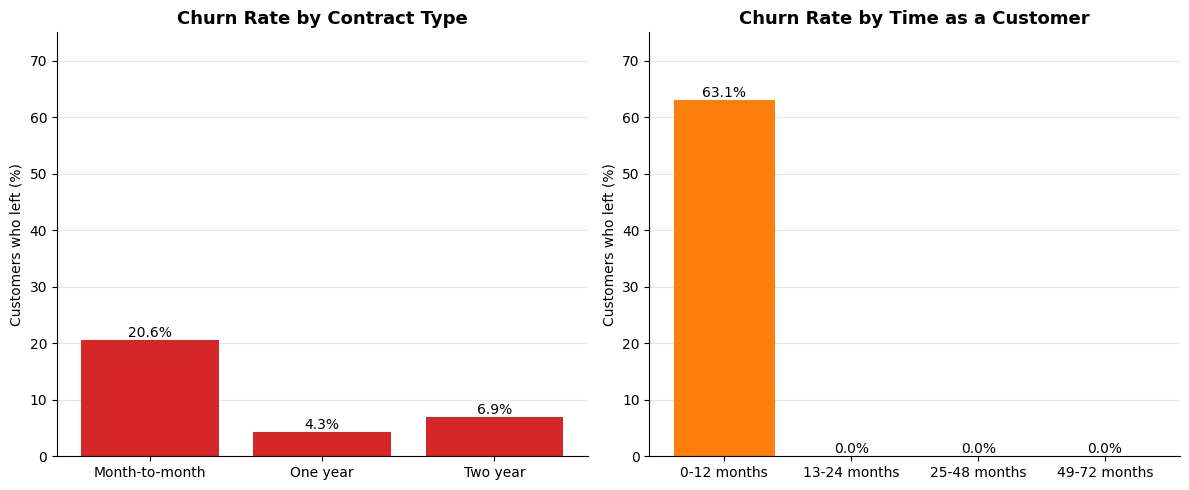

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 4: Dashboard - 5 charts with 5 different chart types

import os
import shutil
import matplotlib.pyplot as plt
import numpy as np

os.makedirs('charts', exist_ok=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']


def tidy(ax):
    """Make a chart look clean and professional."""
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)


# ---------- Chart 1: Bar chart - total sales by product ----------
fig, ax = plt.subplots(figsize=(8, 5))
data = by_product['Total_Sales'].sort_values()
bars = ax.barh(data.index, data.values / 1_000_000, color='#1f77b4')
for bar, value in zip(bars, data.values):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f"Rs.{value / 1_000_000:.2f}M", va='center')
ax.set_title('Total Sales by Product', fontsize=14, fontweight='bold')
ax.set_xlabel('Sales (Rs. millions)')
ax.set_xlim(0, data.max() / 1_000_000 * 1.2)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig('charts/1_sales_by_product_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Chart 2: Line chart - monthly sales trend ----------
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(by_month['MonthName'], by_month['Total_Sales'] / 1_000_000,
        marker='o', linewidth=2.5, color='#2ca02c')
for x, y in zip(by_month['MonthName'], by_month['Total_Sales'] / 1_000_000):
    ax.annotate(f"{y:.2f}M", (x, y), textcoords='offset points', xytext=(0, 10), ha='center')
ax.set_title('Monthly Sales Trend (April has only 9 days of data)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month (2024)')
ax.set_ylabel('Sales (Rs. millions)')
ax.set_ylim(0, by_month['Total_Sales'].max() / 1_000_000 * 1.2)
tidy(ax)
plt.savefig('charts/2_monthly_sales_line.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Chart 3: Pie chart - share of sales by region ----------
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(by_region['Total_Sales'], labels=by_region.index, autopct='%1.1f%%',
       startangle=90, colors=colors, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax.set_title('Share of Total Sales by Region', fontsize=14, fontweight='bold')
plt.savefig('charts/3_sales_by_region_pie.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Chart 4: Heatmap - sales by product and region (pivot table) ----------
heat = pivot_product_region.drop(index='All', columns='All') / 1_000_000
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(heat.values, cmap='YlOrRd')
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        text_color = 'white' if heat.values[i, j] > heat.values.max() * 0.6 else 'black'
        ax.text(j, i, f"{heat.values[i, j]:.2f}", ha='center', va='center', color=text_color)
ax.set_title('Sales by Product and Region (Rs. millions)', fontsize=14, fontweight='bold')
fig.colorbar(image, ax=ax, label='Sales (Rs. millions)')
plt.savefig('charts/4_product_region_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Chart 5: Churn rate charts (two bar charts side by side) ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(churn_by_contract.index, churn_by_contract['Churn_Rate_%'], color='#d62728')
axes[0].set_title('Churn Rate by Contract Type', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Customers who left (%)')
axes[1].bar(churn_by_tenure.index, churn_by_tenure['Churn_Rate_%'], color='#ff7f0e')
axes[1].set_title('Churn Rate by Time as a Customer', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Customers who left (%)')
for ax in axes:
    tidy(ax)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom')
    ax.set_ylim(0, 75)
plt.tight_layout()
plt.savefig('charts/5_churn_rate_bars.png', dpi=150, bbox_inches='tight')
plt.show()

# Put all charts in one zip file so they are easy to download
shutil.make_archive('charts', 'zip', 'charts')
from google.colab import files
files.download('charts.zip')